In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch
from matplotlib.patches import PathPatch
from matplotlib.path import Path

In [3]:
df = pd.read_csv('AbsTimesHalves.csv')
print(df)

    Group         CS-         CS+ Control
0       1  165.000000  135.000000       y
1       2  241.700000   58.300000       n
2       3  150.000000  150.000000       n
3       4  147.600000  152.400000       y
4       5  261.300000   38.700000       n
5       6  137.200000  162.800000       y
6       7  255.200000   44.800000       n
7       8  175.400000  124.600000       n
8       9  264.000000   36.000000       n
9      10  258.750000   41.250000       n
10     11  126.300000  173.700000       y
11     12  156.400000  143.600000       n
12     13  197.900000  102.100000       n
13     14  234.100000   65.900000       n
14     15  182.900000  117.100000       n
15     16  152.700000  147.300000       y
16     17  169.100000  130.900000       y
17     18  166.200000  133.800000       y
18     19  247.100000   52.900000       n
19     20  156.800000  143.200000       y
20     21  286.200000   13.800000       n
21     22  267.900000   32.100000       n
22     23  257.200000   42.800000 

In [3]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

def map_half(i,num):
    if(i < num/2):
        return 0
    return 1

In [4]:
def marker(filled=False):
    if (filled):
        return 'o'
    pts = np.linspace(0, np.pi * 2, 24)
    circ = np.c_[np.sin(pts) / 2, -np.cos(pts) / 2]
    vert = np.r_[circ, circ[::-1] * .7]
    return Path(vert)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


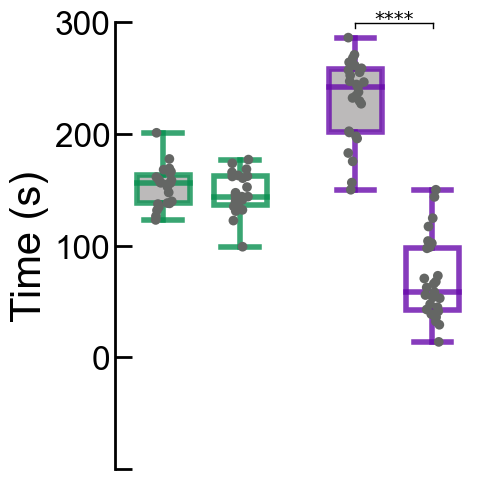

In [10]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']
colors = ["black","black"]
colors = ["#646664","#646664"]
colors_boxplot = ['#078f4f', "#680aab"]
colors_boxplot_filling = ['#aba9a9',"#aba9a9"]


ax = sns.stripplot(
    data=newdf,
    hue='Experimental Condition',
    y='Left preference',
    x='control',
    marker=marker(True),
    palette=colors,
    size=7,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    hue='Experimental Condition',
    y='Left preference',
    x='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)

#plt.axhline(linewidth=2, color='lightgrey',ls='--')

data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches


for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[map_half(i,len(box_patches))]
    col_fill = colors_boxplot_filling[map_half(i,len(box_patches))]
    facecolor = col_fill if i%2==0 else 'None'
    patch.set_edgecolor(col)
    patch.set_facecolor(facecolor)
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

        

#handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["", ""],loc=2)

plt.legend([],[], frameon=False)

ax.set_xticklabels([], fontsize = 26)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.spines['left'].set_color('black')


ax.set_xlabel("",fontsize=20)

###


ax.set_yticks(np.arange(0,301,100), fontname='Arial')
ax.set_yticks(np.arange(-100,301,100), fontname='Arial')
ax.set_yticklabels(['','0','100','200','300'],fontname='Arial')


ax.set_xticks('')

ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)

plt.legend([],[], frameon=False)


ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Time (s)', fontsize = 30, fontname='Arial')


ax.set_ylim([-100,300])
ax.set_xlim([-0.45,1.5])

#significance(ax,0,data_ratio,newdf.loc[newdf['control']=='y']['Left preference'].max()+17,text=text_boxplot[0],offset=-4,whisker=4)
significance(ax,1,data_ratio,newdf.loc[newdf['control']=='n']['Left preference'].max()+17,text=text_boxplot[1],offset=-4,whisker=4)


fig = ax.get_figure()
adjust_box_widths(fig, 0.7)
fig.set_size_inches(5.1,4.9)
ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)

plt.setp(boxplot.patches, linestyle='-')
plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig_AbsTimesHalves.jpg",dpi=600,bbox_inches='tight')
plt.savefig('Fig_AbsTimesHalves.eps', format='eps', dpi=600)

